# Active learning on the recombined kinase ligand space: one seed, all three strategies

All three strategies share one starting set, so their results are directly comparable:

| strategy | which generated molecules are scored | which scored molecules are modified |
|---|---|---|
| `greedy`  | the best predicted ones | the best scoring ones, spread over AP clusters |
| `diverse` | spread over AP clusters | the best scoring ones, spread over AP clusters |
| `random`  | at random | at random |

- `active_learning.py` holds the loop and the model
- `analysis_utils.py` holds the analysis, applied to each strategy in the same way
- `run_utils.py` handles seeding and saves each result file with a `.json` of its parameters

One strategy takes roughly 8 to 9 minutes for 20 cycles, so the run cell below takes
about half an hour for all three.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from rdkit import RDLogger

import acquisition_filtering
import active_learning as al
import analysis_utils as an
import oracle as ora
import utils
from run_utils import figure_parameters, new_run_timestamp, save_figure, save_results

RDLogger.DisableLog("rdApp.*")

In [2]:
HERE = Path(_dh[-1])

PATH_FRAGMENT_LIB = HERE / ".." / "data" / "fragment_library_custom_filtered"
PATH_SUBSET_LIB = HERE / ".." / "data" / "diverse_recomb_library_larger"
PATH_AFFINITIES = (
    HERE / ".." / "data" / "recombination_library"
    / "predictions_skip_hyde_random_split_large.csv"
)
PATH_INITIAL_MOLS = (
    HERE / ".." / "data" / "recombination_library" / "combinatorial_library_large.sdf"
)
PATH_RESULTS = HERE / ".." / "Results" / "notebook_single_seed"
PATH_RESULTS.mkdir(parents=True, exist_ok=True)

## Settings

This is the only cell to edit for a new run. The values are `run_grid.py`'s defaults;
change them here and the same change on the command line keeps the two in step.

In [3]:
SEED = 0

settings = al.Settings(
    n_initial=100,      # molecules in the starting set, a plain random sample
    n_cycles=20,        # active learning cycles
    n_parents=20,       # scored molecules modified to generate new ones, per cycle
    n_query=50,         # molecules that should come back with a value, per cycle
    # a cycle keeps sending molecules to the oracle until n_query of them return a value,
    # but never sends more than this many. None spends exactly n_query calls, so cycles
    # that hit molecules the oracle cannot score end up short.
    max_oracle_calls=None,
    max_generated=1000, # max. new molecules generated per cycle
)

#   Strategy settings: 
#   query_strategy   : which generated molecules are sent to the oracle
#   parent_selection : which scored molecules are modified, "top scoring" or "random"
#   clustering       : with "top scoring", pick the parents spread over the AP clusters
#                      instead of taking the best ones for more diversity and stability
STRATEGIES = [
    al.Strategy(
        "greedy",
        query_strategy=acquisition_filtering.greedy,
        parent_selection="top scoring",
        clustering=True,
    ),
    al.Strategy(
        "diverse",
        query_strategy=acquisition_filtering.sample_diverse,
        parent_selection="top scoring",
        clustering=True,
    ),
    al.Strategy(
        "random",
        query_strategy=acquisition_filtering.random_selection,
        parent_selection="random",
    ),
]

# the same colours as the other result notebooks
COLORS = {"greedy": "C0", "diverse": "C1", "random": "grey"}

# start time of this run, part of every output file name
RUN_TIMESTAMP = new_run_timestamp()

## Fragment library, oracle and starting set

The oracle looks its values up in the table of precomputed kinodata predictions, so a
query is a lookup rather than a docking run. Molecules missing from that table come back
without a value, which is why a cycle can end up with fewer than `n_query` molecules.

In [4]:
fragment_library = utils.read_fragment_library(PATH_FRAGMENT_LIB)
subset_library = utils.read_fragment_library(PATH_SUBSET_LIB)
oracle = ora.Oracle(fragment_library, subset_library, PATH_AFFINITIES)

In [5]:
vals_init, mols_init, fps_init, smi_init, data_mean, data_std = al.initial_distribution(
    oracle, PATH_INITIAL_MOLS, settings.n_initial, SEED
)
initial = (vals_init, mols_init, fps_init, smi_init)
print(f"starting set of {len(mols_init)} molecules, "
      f"mean {data_mean:.3f}, std {data_std:.3f}")

# input files, recorded in the .json file saved next to every result file
EXTRA_PARAMS = dict(
    initial_library=PATH_INITIAL_MOLS,
    affinity_file=PATH_AFFINITIES,
    fragment_library=PATH_FRAGMENT_LIB,
    subset_library=PATH_SUBSET_LIB,
    run_mode="notebook, one seed, all strategies in one process",
)

84669 molecules with an oracle value
starting set of 100 molecules, mean 6.640, std 0.382


## Run

Every strategy starts from the same starting set and re-seeds before its loop, so
repeating this gives the same result.

In [6]:
results = al.run_strategies(
    oracle,
    STRATEGIES,
    settings,
    initial,
    data_mean,
    data_std,
    seed=SEED,
    run_timestamp=RUN_TIMESTAMP,
    extra_params=EXTRA_PARAMS,
)

greedy:   0%|          | 0/20 [00:00<?, ?it/s]

len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50
len mols: 50, len affinity: 50


diverse:   0%|          | 0/20 [00:00<?, ?it/s]

len mols: 50, len affinity: 50
len mols: 1000, len affinity: 1000
len mols: 50, len affinity: 50
len mols: 909, len affinity: 909
len mols: 50, len affinity: 50
len mols: 697, len affinity: 697
len mols: 50, len affinity: 50
len mols: 832, len affinity: 832
len mols: 50, len affinity: 50
len mols: 888, len affinity: 888
len mols: 50, len affinity: 50
len mols: 763, len affinity: 763
len mols: 50, len affinity: 50
len mols: 712, len affinity: 712
len mols: 50, len affinity: 50
len mols: 770, len affinity: 770
len mols: 50, len affinity: 50
len mols: 834, len affinity: 834
len mols: 50, len affinity: 50
len mols: 801, len affinity: 801
len mols: 50, len affinity: 50
len mols: 932, len affinity: 932
len mols: 50, len affinity: 50
len mols: 903, len affinity: 903
len mols: 50, len affinity: 50
len mols: 866, len affinity: 866
len mols: 50, len affinity: 50
len mols: 951, len affinity: 951
len mols: 50, len affinity: 50
len mols: 946, len affinity: 946
len mols: 50, len affinity: 50
len mol

random:   0%|          | 0/20 [00:00<?, ?it/s]

In [7]:
results_dfs = {name: result.results_df(data_mean, data_std)
               for name, result in results.items()}

summary = pd.DataFrame({
    "molecules scored": {n: len(df) for n, df in results_dfs.items()},
    "oracle calls": {n: int(sum(r.oracle_calls)) for n, r in results.items()},
    "best affinity": {n: df["binding affinity"].max() for n, df in results_dfs.items()},
    "mean affinity": {n: df["binding affinity"].mean() for n, df in results_dfs.items()},
})
summary

,molecules scored,oracle calls,best affinity,mean affinity
greedy,704,1000,7.937722,7.244155
diverse,530,1000,7.756205,7.038323
random,706,1000,7.627098,6.619775


## Save

Each strategy gets a `.csv` and a `.json` with all parameters of the run. Existing files
are never overwritten, so a second run of this cell fails rather than replacing them.

In [8]:
for name, result in results.items():
    save_results(
        results_dfs[name],
        f"active_learning_kinodata_{name}_notebook",
        PATH_RESULTS,
        result.params,
    )

saved active_learning_kinodata_greedy_notebook_seed0_2026-10-28_11-40-59.csv and active_learning_kinodata_greedy_notebook_seed0_2026-10-28_11-40-59.json
saved active_learning_kinodata_diverse_notebook_seed0_2026-10-28_11-40-59.csv and active_learning_kinodata_diverse_notebook_seed0_2026-10-28_11-40-59.json
saved active_learning_kinodata_random_notebook_seed0_2026-10-28_11-40-59.csv and active_learning_kinodata_random_notebook_seed0_2026-10-28_11-40-59.json


## Binding affinity per cycle

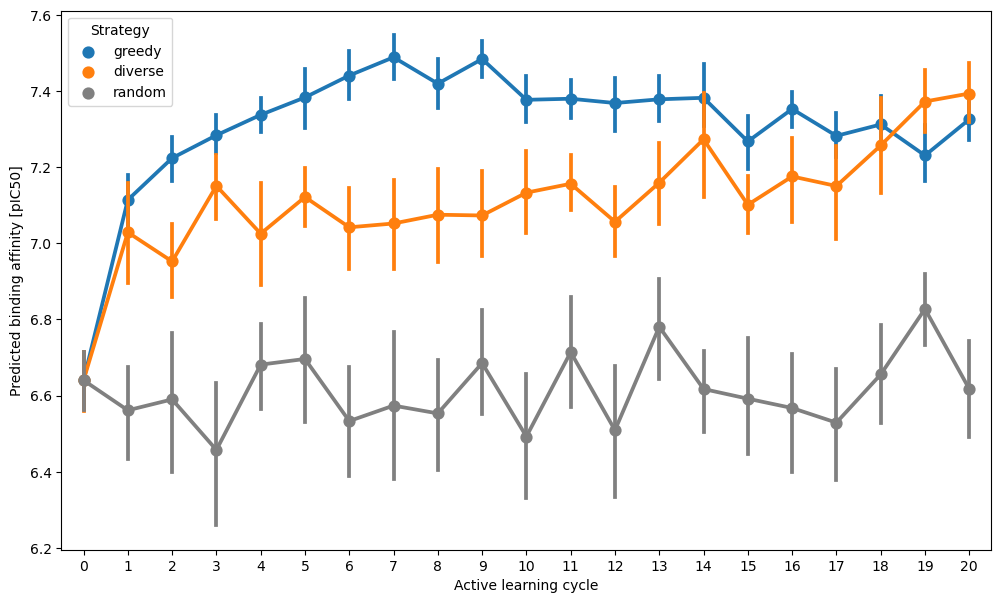

In [9]:
merged_df = an.merge_results(results_dfs)

plt.figure(figsize=(12, 7))
sns.pointplot(x="cycle", y="binding affinity", data=merged_df, hue="strategy",
              palette=COLORS)
plt.xlabel("Active learning cycle")
plt.ylabel("Predicted binding affinity [pIC50]")
plt.legend(title="Strategy")
plt.show()